# Cost of Living vs. Country Development

This notebook combines all three parts of the Data Engineering project:

1. **Part 1 — Numbeo Web Scraping and Data Cleaning**   Usmanov Shingiskhan (23B031932)
2. **Part 2 — World Bank API and Dataset Merging**. Akniet Barakhan (24B031687)
3. **Part 3 — Data Analysis, Visualizations, and Conclusions**. Kenzhebay Ayala (24B031838)


## Part 1 — Numbeo Web Scraping and Data Cleaning


In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
print("OK", requests.__version__, pd.__version__)

OK 2.32.4 2.2.3


In [2]:
headers = {"User-Agent": "Mozilla/5.0 (student project; data course)"}

r = requests.get("https://www.numbeo.com/robots.txt", headers=headers, timeout=15)
print("Status code:", r.status_code)
print(r.text[:2000])

Status code: 200
User-agent: *
Disallow: /heavy_crawling.any
Disallow: /DEPRECATED/




In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

headers = {"User-Agent": "Mozilla/5.0 (student project; data course)"}

r = requests.get("https://www.numbeo.com/robots.txt", headers=headers, timeout=15)
print("Status code:", r.status_code)
print(r.text[:2000])

Status code: 200
User-agent: *
Disallow: /heavy_crawling.any
Disallow: /DEPRECATED/




In [4]:
url = "https://www.numbeo.com/cost-of-living/rankings_by_country.jsp"

response = requests.get(url, headers=headers, timeout=15)
print("Status code:", response.status_code)
print("Page length:", len(response.text))

soup = BeautifulSoup(response.text, "lxml")
print(soup.title.text)

Status code: 200
Page length: 88876
Cost of Living Index by Country 2026 Mid-Year


In [5]:
url = "https://www.numbeo.com/cost-of-living/rankings_by_country.jsp"

response = requests.get(url, headers=headers, timeout=15)
print("Status code:", response.status_code)
print("Page length:", len(response.text))

soup = BeautifulSoup(response.text, "html.parser")
print(soup.title.text)

Status code: 200
Page length: 88874
Cost of Living Index by Country 2026 Mid-Year


In [6]:
table = soup.find("table", id="t2")
print("Found table:", table is not None)

columns = [th.get_text(strip=True) for th in table.find("thead").find_all("th")]
print("Columns:", columns)

data = []
for row in table.find("tbody").find_all("tr"):
    cells = [td.get_text(strip=True) for td in row.find_all("td")]
    if cells:
        data.append(cells)

df_raw = pd.DataFrame(data, columns=columns)

print("Shape:", df_raw.shape)
print(df_raw.head())
print(df_raw.dtypes)

Found table: True
Columns: ['Rank', 'Country', 'Cost of Living Index', 'Rent Index', 'Cost of Living Plus Rent Index', 'Groceries Index', 'Restaurant Price Index', 'Local Purchasing Power Index']
Shape: (152, 8)
  Rank          Country Cost of Living Index Rent Index  \
0               Bermuda                135.8      105.9   
1        Cayman Islands                119.9       74.1   
2           Switzerland                109.8       47.9   
3       Solomon Islands                104.1       20.2   
4          Turkmenistan                101.6       23.9   

  Cost of Living Plus Rent Index Groceries Index Restaurant Price Index  \
0                          122.1           149.0                  136.8   
1                           99.0           126.9                   99.7   
2                           81.5           109.5                  108.1   
3                           65.7            66.8                   45.8   
4                           66.1           116.3          

In [7]:
numbeo = df_raw[["Country", "Cost of Living Index", "Rent Index",
                 "Groceries Index", "Restaurant Price Index",
                 "Local Purchasing Power Index"]].copy()

In [8]:
numbeo.columns = ["country", "cost_of_living", "rent", "groceries",
                  "restaurant_price", "purchasing_power"]

In [9]:
numbeo["country"] = numbeo["country"].str.strip()
numbeo = numbeo.replace("", pd.NA)

In [10]:
num_cols = ["cost_of_living", "rent", "groceries",
            "restaurant_price", "purchasing_power"]

In [11]:
for col in num_cols:
    numbeo[col] = pd.to_numeric(numbeo[col], errors="coerce")


print("Missing values:\n", numbeo.isna().sum())
print("Duplicate rows:", numbeo.duplicated().sum())
print("Duplicate countries:", numbeo["country"].duplicated().sum())


numbeo_clean = (numbeo.drop_duplicates(subset="country")
                      .dropna()
                      .reset_index(drop=True))

print("Shape after cleaning:", numbeo_clean.shape)
print(numbeo_clean.dtypes)
print(numbeo_clean.head())

Missing values:
 country             0
cost_of_living      0
rent                0
groceries           0
restaurant_price    0
purchasing_power    0
dtype: int64
Duplicate rows: 0
Duplicate countries: 0
Shape after cleaning: (152, 6)
country              object
cost_of_living      float64
rent                float64
groceries           float64
restaurant_price    float64
purchasing_power    float64
dtype: object
           country  cost_of_living   rent  groceries  restaurant_price  \
0          Bermuda           135.8  105.9      149.0             136.8   
1   Cayman Islands           119.9   74.1      126.9              99.7   
2      Switzerland           109.8   47.9      109.5             108.1   
3  Solomon Islands           104.1   20.2       66.8              45.8   
4     Turkmenistan           101.6   23.9      116.3              88.4   

   purchasing_power  
0             104.3  
1             144.9  
2             165.7  
3              13.2  
4              18.5  


In [12]:
print(numbeo_clean.describe().round(1))

print("\nMost expensive 5:")
print(numbeo_clean.nlargest(5, "cost_of_living")[["country", "cost_of_living"]])

print("\nCheapest 5:")
print(numbeo_clean.nsmallest(5, "cost_of_living")[["country", "cost_of_living"]])

print("\nKazakhstan:")
print(numbeo_clean[numbeo_clean["country"] == "Kazakhstan"])

       cost_of_living   rent  groceries  restaurant_price  purchasing_power
count           152.0  152.0      152.0             152.0             152.0
mean             48.3   18.4       50.5              44.1              66.8
std              21.2   14.7       21.6              23.3              43.1
min              18.1    2.4       18.8              10.9               2.4
25%              33.8    9.7       35.3              26.7              33.6
50%              43.9   13.6       43.9              39.0              56.0
75%              57.0   22.1       64.6              55.4              95.2
max             135.8  105.9      149.0             136.8             259.3

Most expensive 5:
           country  cost_of_living
0          Bermuda           135.8
1   Cayman Islands           119.9
2      Switzerland           109.8
3  Solomon Islands           104.1
4     Turkmenistan           101.6

Cheapest 5:
      country  cost_of_living
151     India            18.1
150     Libya 

### Data quality note
Some small or isolated economies (e.g., Solomon Islands, Turkmenistan) appear
among the most expensive countries despite very low purchasing power. This may
reflect limited price data for these places (Numbeo's data is crowd-sourced, so
countries with fewer contributors can be less reliable). We keep them in the
dataset but treat them as potential outliers in the analysis.

In [13]:
numbeo_clean.to_csv("numbeo_clean.csv", index=False)
print("Saved:", numbeo_clean.shape)

Saved: (152, 6)


   ### Numbeo scraping and cleaning summary
   - Source: Numbeo Cost of Living Index by Country (2026 Mid-Year), scraped with
     `requests` and `BeautifulSoup`.
   - Raw table: 152 countries, 8 columns (all text).
   - Cleaning: dropped the empty `Rank` column and the combined "Cost of Living
     Plus Rent" column, renamed columns, converted indexes to numeric, checked
     for missing values and duplicates (none found).
   - Result: `numbeo_clean` with 152 rows and 6 columns: country, cost_of_living,
     rent, groceries, restaurant_price, purchasing_power.

## Part 2 — World Bank API and Dataset Merging


In [ ]:
if "numbeo_clean" not in globals():
    numbeo_clean = pd.read_csv("numbeo_clean.csv")


In [ ]:
import requests, pandas as pd

YEAR = 2022  
indicators = {
    "NY.GDP.PCAP.CD": "gdp_per_capita",
    "SP.DYN.LE00.IN": "life_expectancy",
    "SL.UEM.TOTL.ZS": "unemployment",
}

# 1. List of countries
r = requests.get("https://api.worldbank.org/v2/country",
                 params={"format": "json", "per_page": 400}).json()[1]
countries = pd.DataFrame([{"iso3": c["id"], "country": c["name"],
                           "region": c["region"]["value"]} for c in r])
countries = countries[countries["region"] != "Aggregates"]

# 2. Indicators
df = countries[["iso3", "country"]].copy()
for code, name in indicators.items():
    data = requests.get(
        f"https://api.worldbank.org/v2/country/all/indicator/{code}",
        params={"format": "json", "date": YEAR, "per_page": 400}).json()[1]
    s = pd.DataFrame([{"iso3": d["countryiso3code"], name: d["value"]} for d in data])
    df = df.merge(s, on="iso3", how="left")

# 3. Cleaning
df = df.drop_duplicates("iso3")
df[list(indicators.values())] = df[list(indicators.values())].apply(pd.to_numeric, errors="coerce")
print(df.isna().sum())
df = df.dropna(subset=list(indicators.values()))  

# 4. Name of countries
mapping = {
    "Russian Federation": "Russia", "Korea, Rep.": "South Korea",
    "Turkiye": "Turkey", "Egypt, Arab Rep.": "Egypt", "Iran, Islamic Rep.": "Iran",
    "Slovak Republic": "Slovakia", "Czechia": "Czech Republic",
    "Viet Nam": "Vietnam", "Hong Kong SAR, China": "Hong Kong",
}
df["country"] = df["country"].replace(mapping).str.strip()

# 5. Merge
numbeo_clean["country"] = numbeo_clean["country"].str.strip()
check = df.merge(numbeo_clean, on="country", how="outer", indicator=True)
print(check[check["_merge"] != "both"][["country", "_merge"]])  

final_dataset = df.merge(numbeo_clean, on="country", how="inner")
final_dataset.to_csv("final_dataset.csv", index=False)

iso3                0
country             0
gdp_per_capita      8
life_expectancy     0
unemployment       31
dtype: int64
                   country      _merge
9                  Bahamas  right_only
10            Bahamas, The   left_only
13                Barbados   left_only
17                   Benin   left_only
18                 Bermuda  right_only
..                     ...         ...
198              Venezuela  right_only
199          Venezuela, RB   left_only
201  Virgin Islands (U.S.)   left_only
202     West Bank and Gaza   left_only
203                  Yemen  right_only

[79 rows x 2 columns]


## Part 3 — Data Analysis and Visualization

This section analyzes the final merged dataset using descriptive statistics,
correlation analysis, and visualizations.


### 3.1 Dataset Overview


In [16]:
print("Dataset shape:", final_dataset.shape)
display(final_dataset.head())

print("\nData types:")
print(final_dataset.dtypes)

print("\nMissing values:")
print(final_dataset.isnull().sum())

print("\nDuplicate rows:", final_dataset.duplicated().sum())


Dataset shape: (127, 10)


,iso3,country,gdp_per_capita,life_expectancy,unemployment,cost_of_living,rent,groceries,restaurant_price,purchasing_power
0,AFG,Afghanistan,357.261153,65.617,14.100,21.6,2.5,20.2,15.3,38.5
1,AGO,Angola,3598.536691,64.246,14.124,35.6,17.4,34.2,29.1,259.3
2,ALB,Albania,7756.961887,78.769,10.785,44.7,11.9,46.6,39.3,46.9
3,ARE,United Arab Emirates,50759.759019,80.487,2.872,55.6,36.3,45.4,57.9,113.4
4,ARG,Argentina,13962.189409,75.806,6.805,44.9,12.8,43.8,52.1,44.8



Data types:
iso3                 object
country              object
gdp_per_capita      float64
life_expectancy     float64
unemployment        float64
cost_of_living      float64
rent                float64
groceries           float64
restaurant_price    float64
purchasing_power    float64
dtype: object

Missing values:
iso3                0
country             0
gdp_per_capita      0
life_expectancy     0
unemployment        0
cost_of_living      0
rent                0
groceries           0
restaurant_price    0
purchasing_power    0
dtype: int64

Duplicate rows: 0


### 3.2 Descriptive Statistics


In [17]:
display(final_dataset.describe(include="number").round(2))


,gdp_per_capita,life_expectancy,unemployment,cost_of_living,rent,groceries,restaurant_price,purchasing_power
count,127.00,127.00,127.00,127.00,127.00,127.00,127.00,127.00
mean,20779.28,74.81,6.62,45.79,16.36,47.50,41.85,67.12
std,26046.60,6.01,4.95,18.67,10.56,18.51,20.59,43.21
min,357.26,54.08,0.13,18.10,2.40,18.80,10.90,8.80
25%,3927.50,71.34,3.54,32.60,9.75,35.05,26.10,34.95
50%,8328.71,75.24,4.99,41.60,13.50,43.30,38.60,55.30
75%,28350.34,80.46,8.17,53.25,20.40,54.95,53.35,92.75
max,123719.66,84.00,33.27,109.80,68.30,116.30,108.10,259.30


### 3.3 Correlation Analysis

The correlation matrix shows the direction and strength of relationships
between the numerical variables.


In [18]:
numeric_data = final_dataset.select_dtypes(include="number")
correlation_matrix = numeric_data.corr()

display(correlation_matrix.round(2))


,gdp_per_capita,life_expectancy,unemployment,cost_of_living,rent,groceries,restaurant_price,purchasing_power
gdp_per_capita,1.00,0.68,-0.25,0.74,0.83,0.72,0.79,0.73
life_expectancy,0.68,1.00,-0.16,0.56,0.51,0.56,0.60,0.58
unemployment,-0.25,-0.16,1.00,-0.24,-0.27,-0.26,-0.17,-0.04
cost_of_living,0.74,0.56,-0.24,1.00,0.82,0.95,0.92,0.52
rent,0.83,0.51,-0.27,0.82,1.00,0.78,0.78,0.56
groceries,0.72,0.56,-0.26,0.95,0.78,1.00,0.88,0.47
restaurant_price,0.79,0.60,-0.17,0.92,0.78,0.88,1.00,0.60
purchasing_power,0.73,0.58,-0.04,0.52,0.56,0.47,0.60,1.00


### 3.4 GDP per Capita vs. Cost of Living


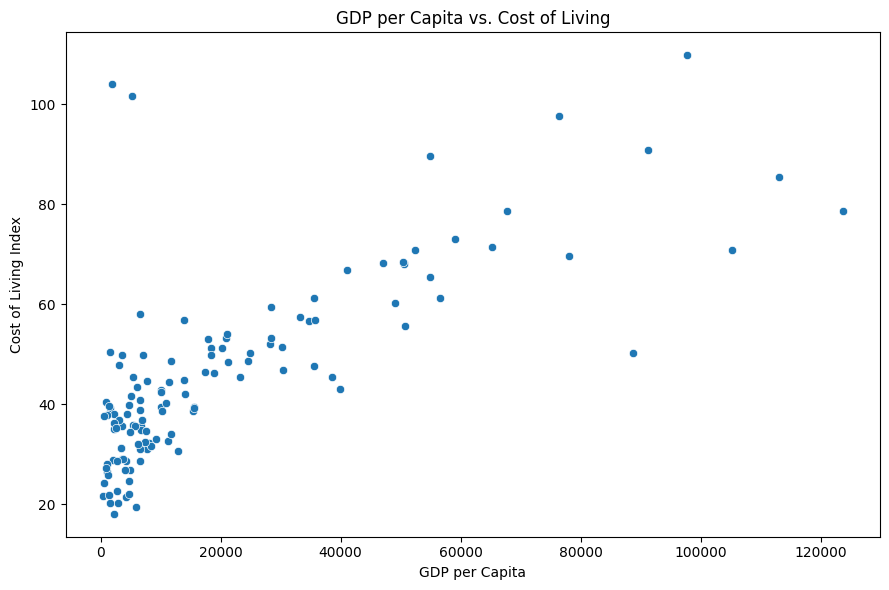

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=final_dataset,
    x="gdp_per_capita",
    y="cost_of_living"
)
plt.title("GDP per Capita vs. Cost of Living")
plt.xlabel("GDP per Capita")
plt.ylabel("Cost of Living Index")
plt.tight_layout()
plt.show()


### 3.5 Correlation Heatmap


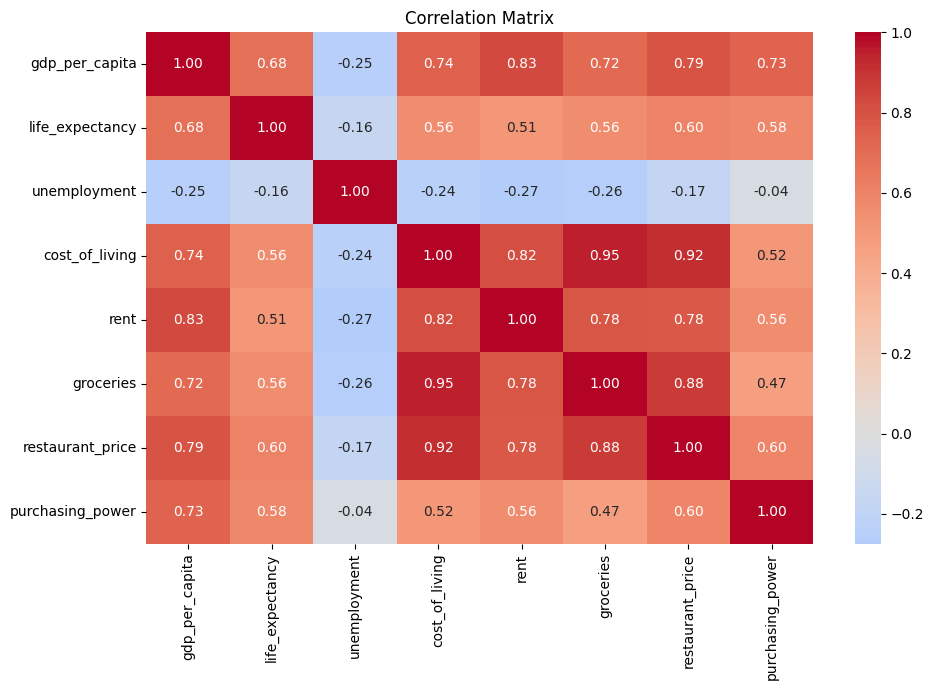

In [20]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


### 3.6 Top 10 Countries by Cost of Living


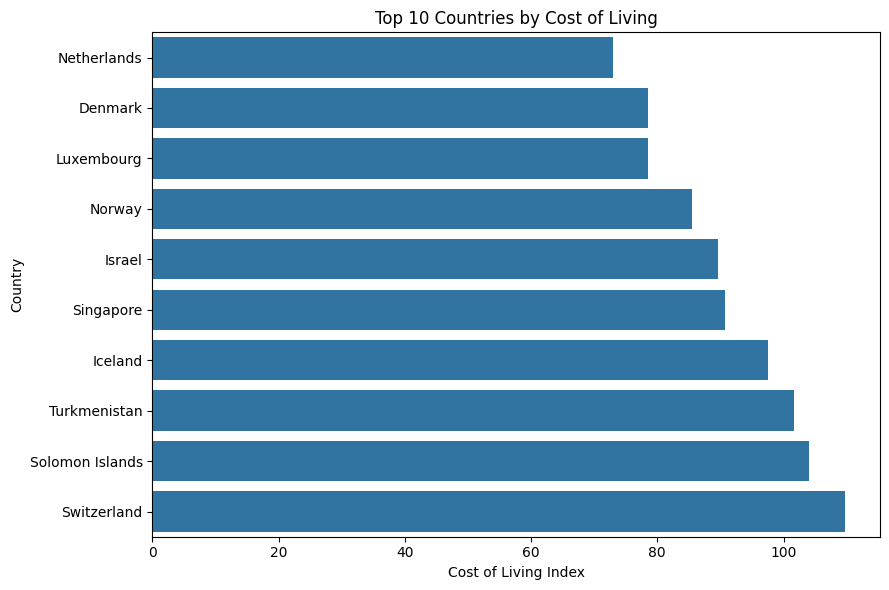

In [21]:
top10 = final_dataset.nlargest(10, "cost_of_living").sort_values("cost_of_living")

plt.figure(figsize=(9, 6))
sns.barplot(data=top10, x="cost_of_living", y="country")
plt.title("Top 10 Countries by Cost of Living")
plt.xlabel("Cost of Living Index")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


### 3.7 Bottom 10 Countries by Cost of Living


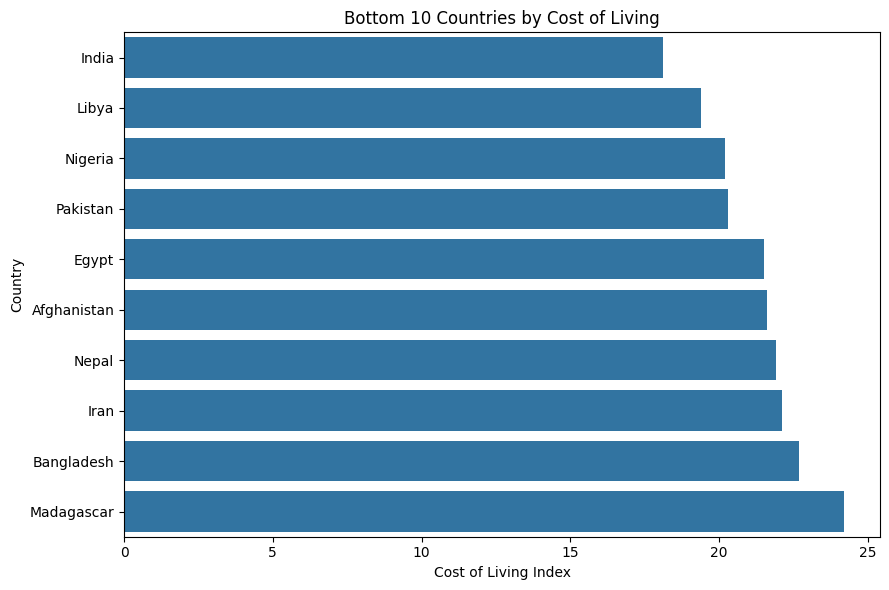

In [22]:
bottom10 = final_dataset.nsmallest(10, "cost_of_living").sort_values("cost_of_living")

plt.figure(figsize=(9, 6))
sns.barplot(data=bottom10, x="cost_of_living", y="country")
plt.title("Bottom 10 Countries by Cost of Living")
plt.xlabel("Cost of Living Index")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


## Conclusion

The project combines Numbeo Cost of Living data with World Bank development
indicators. The final conclusions should be based on the actual results produced
by the analysis above.
